<a href="https://colab.research.google.com/github/klay-10/RFM-customer-segmentation-/blob/main/Loan_Predication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutoral project

###Data Exploration

In [ ]:
# Import Essential Libraries
import math
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from imblearn.over_sampling import SMOTE
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style= "darkgrid", color_codes = True)
import warnings
warnings.filterwarnings('ignore')

###Preprocessing

In [ ]:
# Import Dataset
loan_dataset= pd.read_csv("/content/drive/MyDrive/loan_predication/train_u6lujuX_CVtuZ9i (1).csv")
loan_dataset.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


###BASIC INFO

###check shape , first and last row

In [ ]:
print("row and column", loan_dataset.shape)
display(loan_dataset.head())
display(loan_dataset.tail())

row and column (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


###Check data types and memory structure

In [ ]:
loan_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


###Summary statistics for numerical features

In [ ]:
loan_dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


###Summary statistics for categorical features

In [ ]:
loan_dataset.describe(include="object")

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP002990,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


###Investigate extreme outliners

<Axes: >

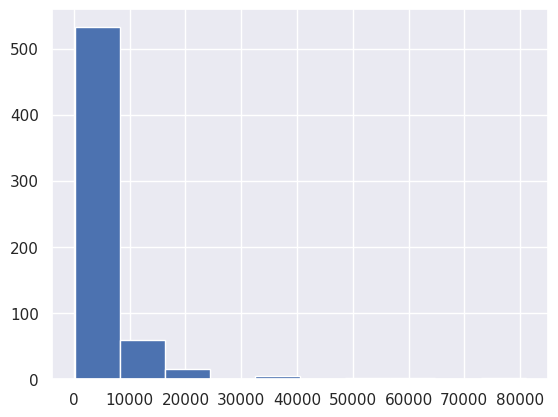

In [ ]:
loan_dataset["ApplicantIncome"].hist()


<Axes: >

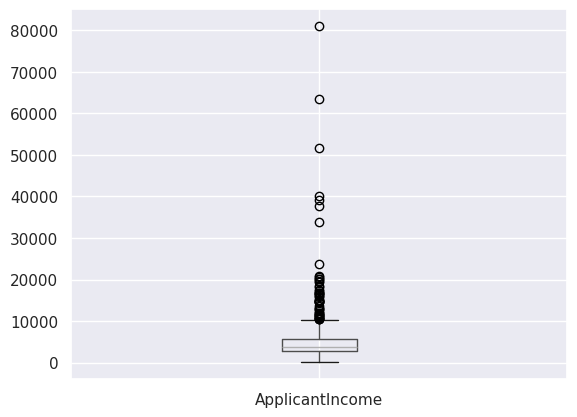

In [ ]:
loan_dataset.boxplot(column='ApplicantIncome')

Check if outliners could be a genuine high-income applicant

In [ ]:
loan_dataset['ApplicantIncome'].sort_values(ascending=False).head(20)

,ApplicantIncome
409,81000
333,63337
171,51763
155,39999
185,39147
443,37719
183,33846
126,23803
506,20833
284,20667


#Clean data

###Handling duplicate

In [ ]:
print("Duplicate before: ",loan_dataset.duplicated().sum())
print(loan_dataset.shape)
#no duplicates then

Duplicate before:  0
(614, 13)


###Check missing values recognized by Pandas

In [ ]:
print(loan_dataset.isna().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


#### Drop Unecessary Variables

In [ ]:
loan_dataset = loan_dataset.drop("Loan_ID", axis=1)

#### Categorical and Continuous Features

In [ ]:
categorical_features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed','Property_Area','Credit_History']
continuous_features = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

###Splitting Loan Dataset

* Train Set: part of the original dataset on which the model learns.
* Validation Set: A part of the main dataset that is not used in the training process and we use it only in the process of improving the performance of the model.
* Test Set: A part of the main dataset on which the performance of the model is tested and reported as the final accuracy. These data should not be used when building the model because these data are real world examples.

Tip: The segmentation should be done on the raw dataset and no pre-processing should be done before it to avoid Data leakage







In [ ]:
# Splitting Data into Train, Validation, and Test Sets
X = loan_dataset.drop(columns='Loan_Status')
Y = loan_dataset['Loan_Status']
# Splitting into Train and Validation Sets
X_train,X_val,y_train,y_val = train_test_split(X,
                                               Y,
                                               test_size=0.2,
                                               stratify=Y,
                                               shuffle=True,
                                               random_state = 40)
# Splitting Validation Set into Validation and Test Sets
X_test,X_val,y_test,y_val = train_test_split(
                                              X_val,
                                              y_val,
                                              test_size=0.5,
                                              stratify=y_val,
                                              shuffle=True,
                                              random_state = 40


)

###Handling Outlier Values

An Outlier is a sample that looks different from the majority of samples in the data set. Your dataset can contain outliers for two reasons:

* Error in data collection and recording process : It is possible that in the process of data collection, values have been wrongly recorded by human (typing error) or computer system in the data collection file.
* Actual data distribution : If the outliers are not due to "error in the data collection and recording process", it means that the actual distribution of the data is like this.

##Distribution Of Numerical Features

In [ ]:
"""*class Plotter:

  def __int__(self,x,y):
    self.X_train = X
    self.y_train = y
    self.fig, self.axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 6))

  def Plot_Box(self,row,col,x):
    ax = self.axes[row,col]
    sns.boxplot(data = self.X_train,X=X,y=self.y_train,ax=ax)
    ax.set_title(f"{X.capitalize()} VS Loan_Status")

  def Show_Plots(self):
    plt.tight_layout()
    plt.show()"""
class Plotter:

    def __init__(self, X, y):
        self.x_train = X
        self.y_train = y
        self.fig, self.axes = plt.subplots(
            nrows=2,
            ncols=2,
            figsize=(10, 6)
        )

    def Plot_Box(self, row, col, x):
        ax = self.axes[row, col]

        sns.boxplot(
            data=self.x_train,
            x=x,
            y=self.y_train,
            ax=ax
        )

        ax.set_title(f"{x} vs. Loan_Status")

    def Show_Plots(self):
        plt.tight_layout()
        plt.show()

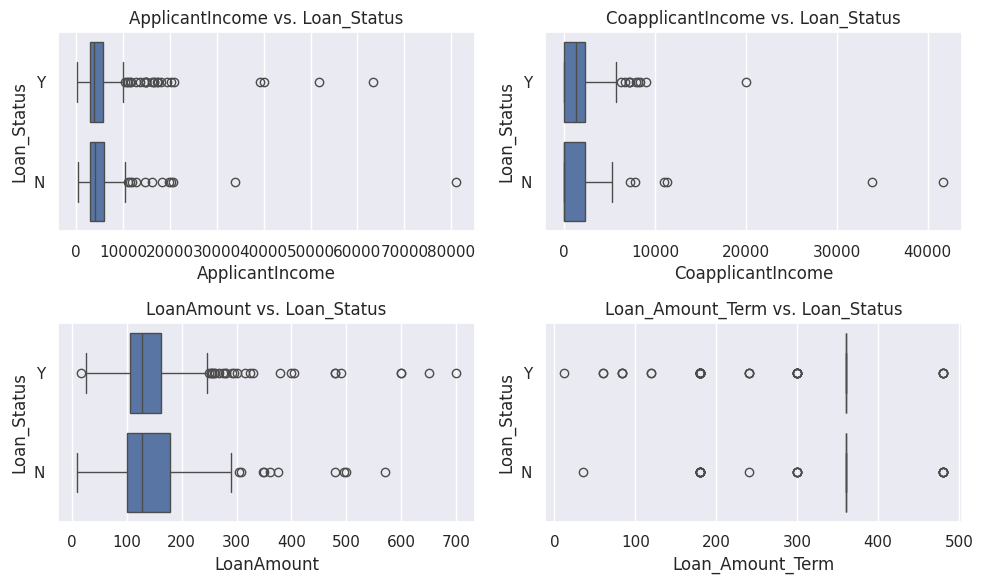

In [ ]:
plot_continuous_features = Plotter(X_train, y_train)

# Plot the box plots
for i, col in enumerate(continuous_features):
    plot_continuous_features.Plot_Box(i // 2, i % 2, x=col)

plot_continuous_features.Show_Plots()

###Distribution Of Categorical Features

In [ ]:
# Create an DataFrame for Analysis Categorical Features
result_df = pd.DataFrame(columns=['Features', 'Category', 'Count'])

for col in categorical_features:
  # Get the value counts for the column
  value_counts = loan_dataset[col].value_counts().reset_index()
  value_counts.columns = ['Category', 'Count']
  value_counts['Features'] = col
  result_df = pd.concat([result_df,value_counts],ignore_index=True)

# Display the result
grouped_by = result_df.groupby('Features').agg({'Category':list,'Count': list})
print(grouped_by)

                                 Category                Count
Features                                                      
Credit_History                 [1.0, 0.0]            [475, 89]
Dependents                  [0, 1, 2, 3+]  [345, 102, 101, 51]
Education        [Graduate, Not Graduate]           [480, 134]
Gender                     [Male, Female]           [489, 112]
Married                         [Yes, No]           [398, 213]
Property_Area   [Semiurban, Urban, Rural]      [233, 202, 179]
Self_Employed                   [No, Yes]            [500, 82]


###Handling Missing Values

The main challenge of missing values is the inability of a wide range of algorithms to deal with them. In other words, many algorithms will fail if they see missing values. Also, the presence of missing values can cause errors in the exploratory analysis of the dataset.

To handle this problem, there are different ways, the most important of which are:

* Remove rows/samples containing missing values
* Remove columns/attributes containing missing values
* Filling missing values with statistical character**istics or a constant value
* Predicting missing values
* Using an algorithm insensitive to missing values

In [ ]:
# Missing Value Analysis
def calculate_missing_values(X_train,X_val,X_test):
  Missing_train = X_train.isna().sum()
  Missing_val = X_val.isna().sum()
  Missing_test = X_test.isna().sum()

  # Convert the series to dataframes
  output_train = pd.DataFrame(Missing_train, columns=['Missing Values X_train'])
  output_val = pd.DataFrame(Missing_val, columns=['Missing Values X_val'])
  output_test = pd.DataFrame(Missing_test, columns=['Missing Values X_test'])

  # Concatenate the dataframes output_train and output_val
  output = pd.concat([output_train,output_val,output_test],axis=1,join ='inner')

  return output

output = calculate_missing_values(X_train,X_val,X_test)

# Define a function to apply the desired styling

def color_cell(value):
    if value >=20 :
        return 'background-color:#2e9ee8; color: black'
    elif value >=10 :
        return 'background-color:#7ac1f0; color: black'
    elif value >=1 :
        return 'background-color:#bdddf2; color: black'
    return 'color: black '

# Apply the styling to the DataFrame
styled_df = output.style.applymap(color_cell)

styled_df
#print(output)


,Missing Values X_train,Missing Values X_val,Missing Values X_test
Gender,6,3,4
Married,2,1,0
Dependents,11,2,2
Education,0,0,0
Self_Employed,29,1,2
ApplicantIncome,0,0,0
CoapplicantIncome,0,0,0
LoanAmount,21,0,1
Loan_Amount_Term,12,2,0
Credit_History,42,4,4


###Finding Rows with 50% or More Null Values

In [ ]:
# Finding Rows with 50% or More Null Values in each sets

def find_rows_with_high_null_values(df):
  threshold = 0.5

  #find the DataFrame name
  df_name = [name for name in globals() if globals()[name] is df][0]

  #mininum number of missing values corresponding to 50%
  null_threshold = math.ceil(threshold * len(df.columns))

  #find rows with 50% or more missing values
  null_rows = df[df.apply(lambda x: x.isnull().sum(), axis=1) >= null_threshold]
  num_null_rows = len(null_rows)

  print(
        f"The number of rows with 50% or more missing values "
        f"in {df_name} is: {num_null_rows}"
    )

# Example usage:
find_rows_with_high_null_values(X_train)
find_rows_with_high_null_values(X_val)
find_rows_with_high_null_values(X_test)

The number of rows with 50% or more missing values in X_train is: 0
The number of rows with 50% or more missing values in X_val is: 0
The number of rows with 50% or more missing values in X_test is: 0


###Handling Missing Values of Continuous Features

As you can see, the dataset has two continuous features that contain missing data. So first of all check some details about them in main dataset

In [ ]:
print(loan_dataset.isna().sum())


Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [ ]:
# calculate mean columns
def calculate_mean(df,columns):
  mean = df[columns].mean().round()
  return mean
for col in ["LoanAmount","Loan_Amount_Term"]:
  print(f"Mean of {col} in Train_set is {calculate_mean(X_train,col)}")
  print(f"Mean of {col} in val_set is {calculate_mean(X_val,col)}")
  print(f"Mean of {col} in Test_set is {calculate_mean(X_test,col)}")

Mean of LoanAmount in Train_set is 148.0
Mean of LoanAmount in val_set is 140.0
Mean of LoanAmount in Test_set is 140.0
Mean of Loan_Amount_Term in Train_set is 341.0
Mean of Loan_Amount_Term in val_set is 346.0
Mean of Loan_Amount_Term in Test_set is 346.0


In [ ]:
def fill_missing_values_by_mean(df, column,mean):
  for col in cols:
    df[col].fillna(df[col].mean(), inplace=True)
  return df
cols = ["LoanAmount", "Loan_Amount_Term"]

# Calculate means ONLY from training data
train_means = X_train[cols].mean()

# Apply training means to all datasets
X_train = fill_missing_values_by_mean(X_train, cols, train_means)
X_val = fill_missing_values_by_mean(X_val, cols, train_means)
X_test = fill_missing_values_by_mean(X_test, cols, train_means)

###Handling Missing Values of Categorical Features
Common methods for handling missing values specific to categorical attributes include:

* Filling with the most common category
* Adding a weight variable
* Creating a new category
* Predicting the missing category: One of the more professional approaches mentioned in the previous chapter is to use a machine learning model for predicting the missing category.

In [ ]:
def Get_Mode(df, cols):
    modes = {}
    for col in cols:
      modes[col] = df[col].mode().iloc[0]
    return modes

categorical_features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed','Property_Area','Credit_History']

train_modes = Get_Mode(X_train, categorical_features)

for col in categorical_features:
    X_train[col] = X_train[col].fillna(train_modes[col])
    X_val[col] = X_val[col].fillna(train_modes[col])
    X_test[col] = X_test[col].fillna(train_modes[col])

In [ ]:
Get_Mode(X_test, categorical_features)

{'Gender': 'Male',
 'Married': 'Yes',
 'Dependents': '0',
 'Education': 'Graduate',
 'Self_Employed': 'No',
 'Property_Area': 'Semiurban',
 'Credit_History': np.float64(1.0)}

In [ ]:
X_train.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [ ]:
X_val.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [ ]:
X_test.isna().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


#Feature Engineering
###Convert Categorical Features

In [ ]:
Nominal_fetaures = ['Gender', 'Married','Education', 'Self_Employed', 'Property_Area']

def encode_categorical_features(df, cols):
  df = df.copy()
  for col in cols:
    dummies = pd.get_dummies(df[col],dtype=int,prefix=col)
    df = pd.concat([df.drop(columns=[col]), dummies], axis=1)
  return df

# Encode the categorical features in the training and test sets
X_train = encode_categorical_features(X_train, Nominal_fetaures)
X_val = encode_categorical_features(X_val, Nominal_fetaures )
X_test = encode_categorical_features(X_test, Nominal_fetaures )

#Then align the validation and test columns with the training columns:
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

#This ensures that:

#Both validation and test sets have the same columns as the training set.

#Any missing dummy columns are added with zeros.

#The column order is consistent."""

In [ ]:
# Encoding Categorical Features
encoder = {'0': 1/4, '1': 2/4, '2': 3/4, '3+': 4/4}
for df in [X_train, X_val, X_test]:
    df["Dependents"] = df['Dependents'].map(encoder)

In [ ]:
X_train.head()


,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Female,Gender_Male,Married_No,Married_Yes,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
101,0.25,4843,3806.0,151.0,360.0,1.0,0,1,1,0,1,0,1,0,0,1,0
116,0.25,3167,2283.0,154.0,360.0,1.0,1,0,0,1,1,0,1,0,0,1,0
191,0.25,12000,0.0,164.0,360.0,1.0,0,1,1,0,1,0,1,0,0,1,0
237,0.25,3463,0.0,122.0,360.0,1.0,1,0,1,0,1,0,0,1,0,0,1
222,0.25,2971,2791.0,144.0,360.0,1.0,0,1,1,0,1,0,1,0,0,1,0


###Balancing TrainSet

In [ ]:
# Convet target column to int
mapping = {"Y":1,"N":0}
y_train = pd.Series(y_train).map(mapping)
y_test = pd.Series(y_test).map(mapping)
y_val = pd.Series(y_val).map(mapping)

#check for NAN in target columns
print(y_train.value_counts(dropna=False))
print(y_val.value_counts(dropna=False))
print(y_test.value_counts(dropna=False))

Loan_Status
1    337
0    154
Name: count, dtype: int64
Loan_Status
1    43
0    19
Name: count, dtype: int64
Loan_Status
1    42
0    19
Name: count, dtype: int64


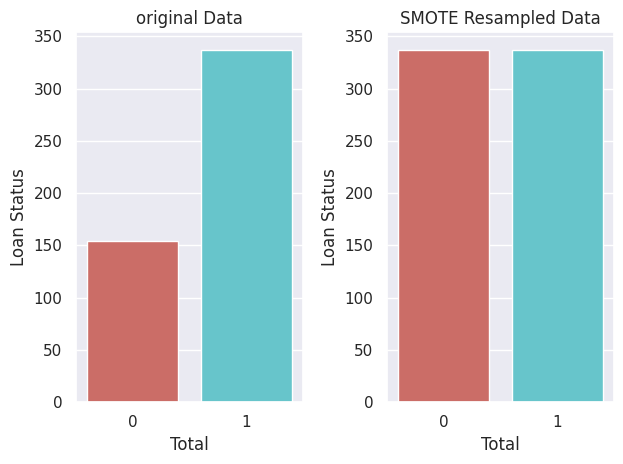

In [ ]:
# Using SMOTE Technique  to Balancing TrainSet
# First figure

plt.subplot(1,2,1)
sns.countplot(x=y_train,data=X_train,palette='hls')
plt.ylabel('Loan Status')
plt.xlabel('Total')
plt.title('original Data')

#second figure
X_train,y_train = SMOTE().fit_resample(X_train,y_train)
plt.subplot(1,2,2)
sns.countplot(x=y_train,data=X_train,palette ='hls')
plt.ylabel('Loan Status')
plt.xlabel('Total')
plt.title('SMOTE Resampled Data')

# Adjust the layout and display the figures
plt.tight_layout()
plt.show()


#Creating Features
##Dimensionality Reduction
###Feature Selection
####Correlation Analysis

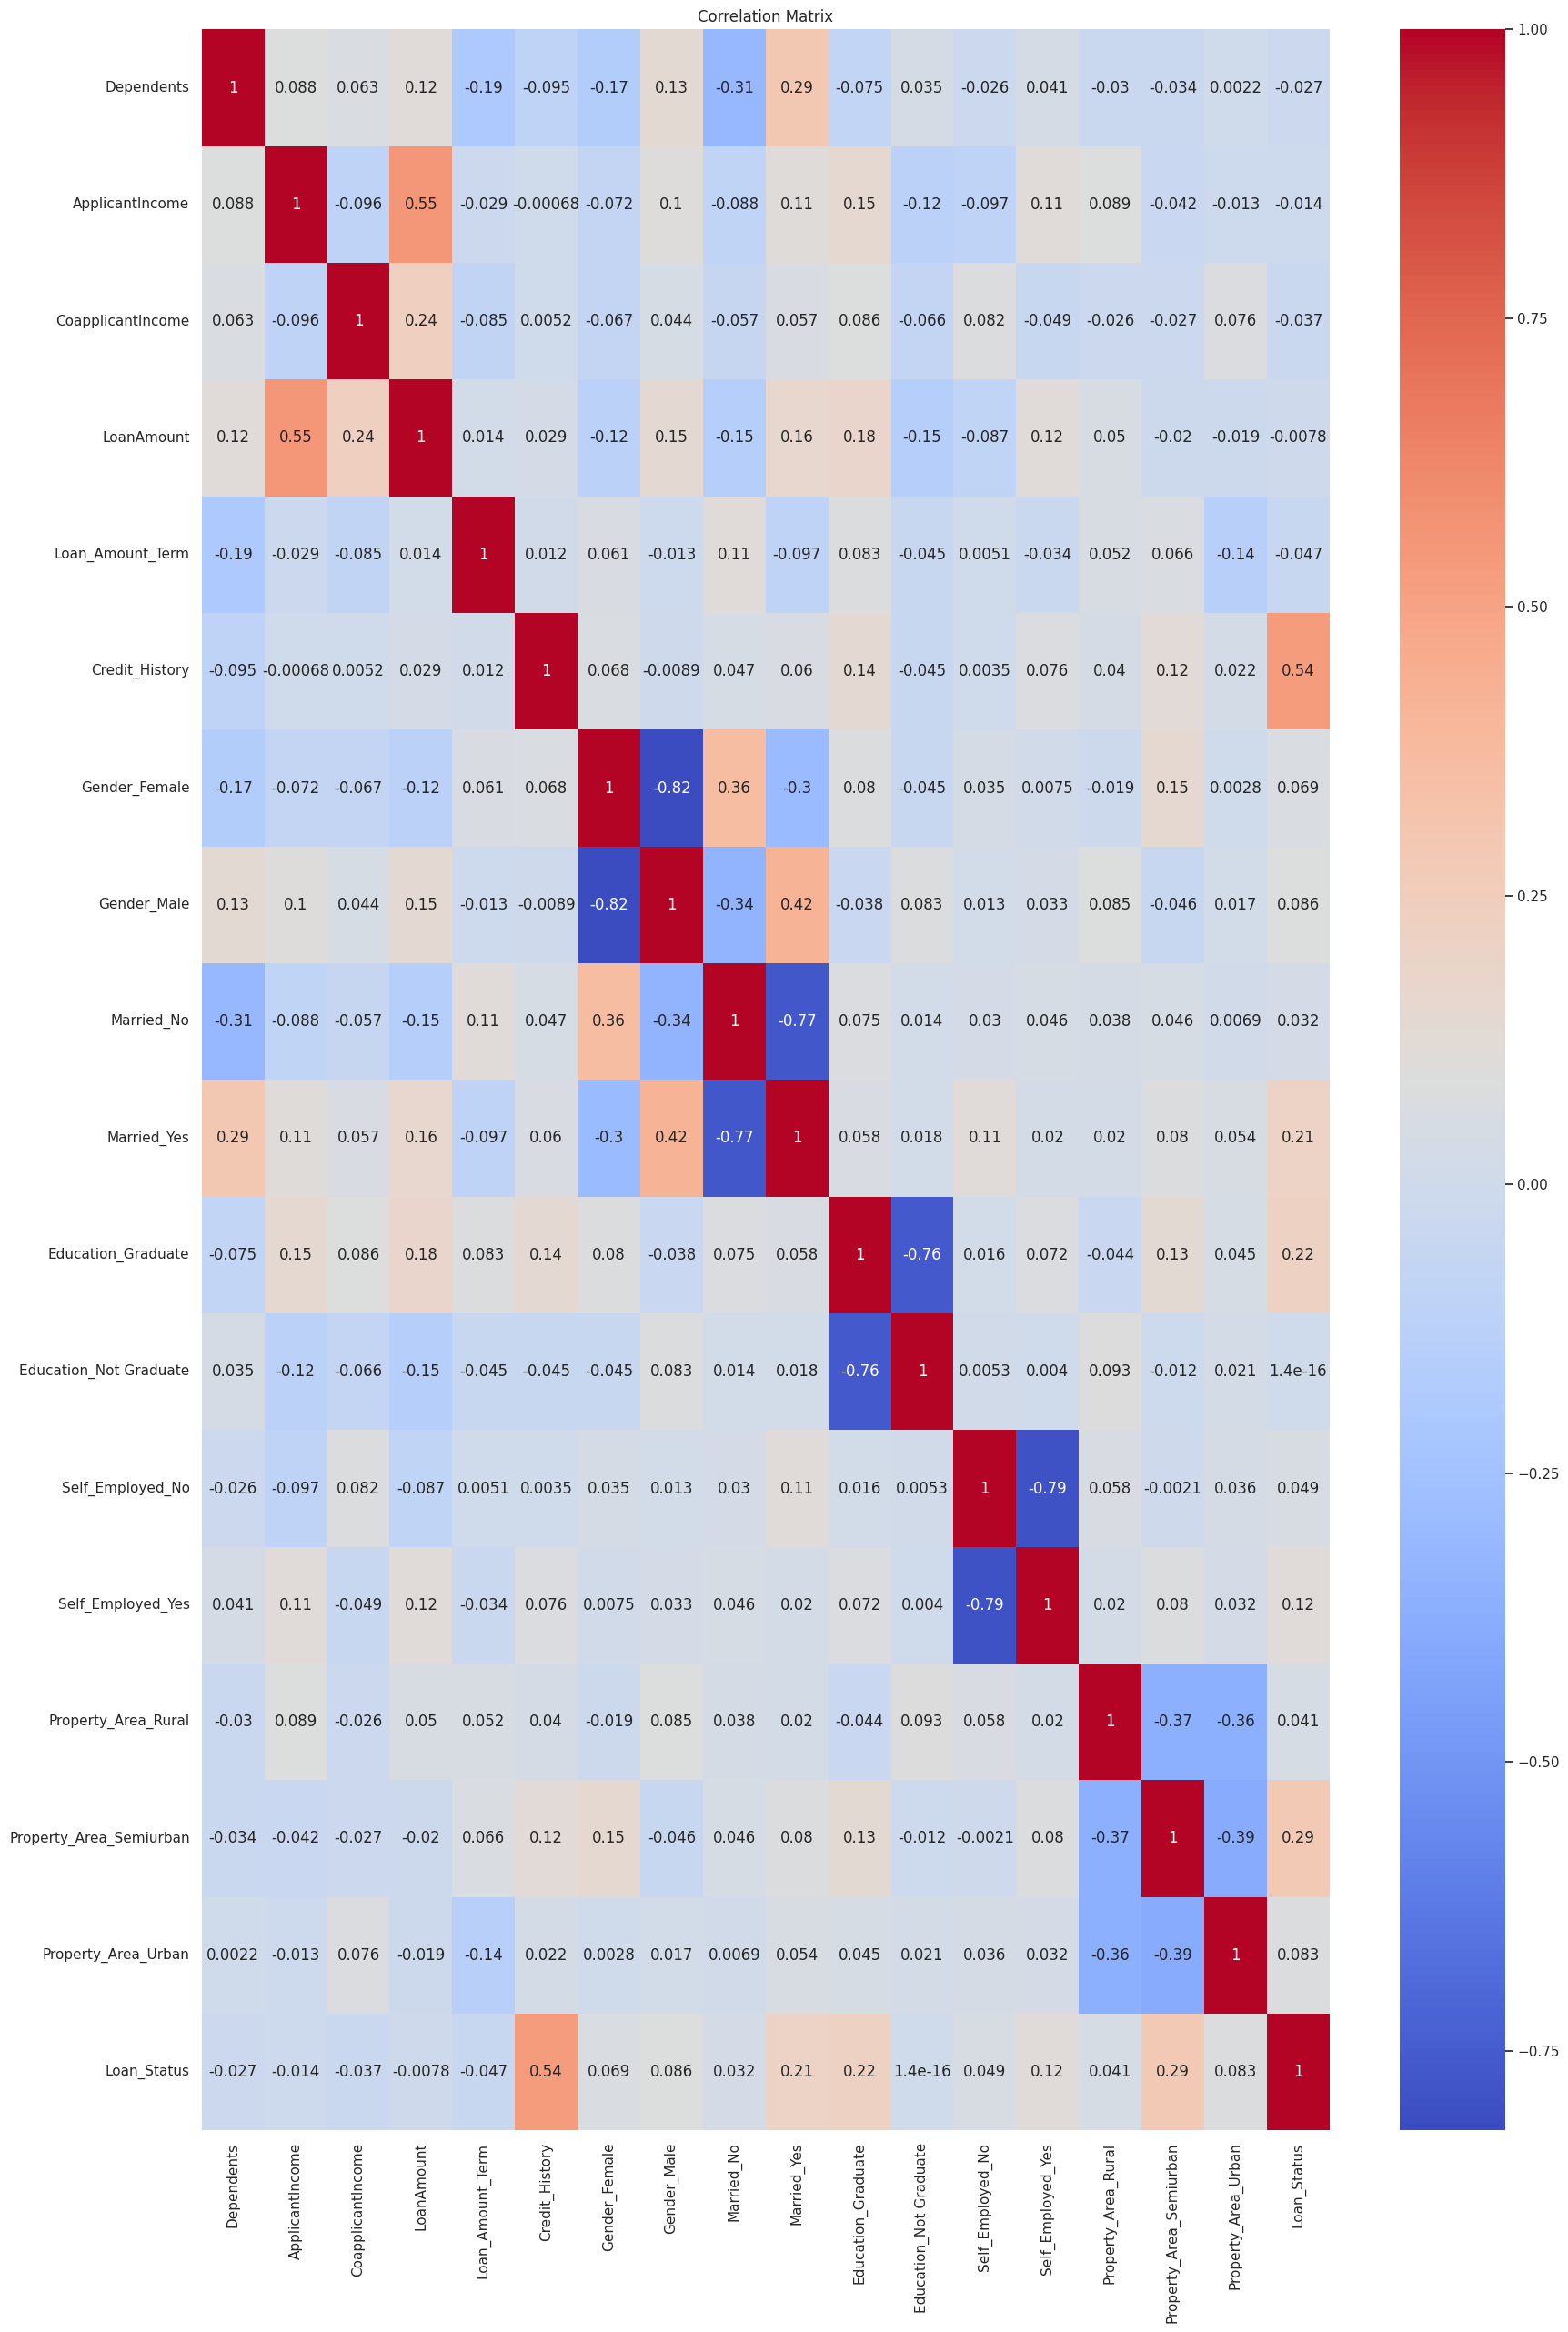

In [ ]:
# Correlation Analysis
train_copy = pd.concat([X_train,y_train], axis=1)
corr_matrix = train_copy.corr()
fig,ax = plt.subplots(figsize= (20,30))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=True, ax=ax)
ax.set_title('Correlation Matrix')
plt.show()

#Establish a baseline model first
Before removing any features, train a model using all your available features and measure its performance on the validation set.

In [ ]:
model = LogisticRegression(max_iter = 10000)

# Train using the training set
model.fit(X_train,y_train)


# Evaluate using the untouched validation set
y_val_pred = model.predict(X_val)


print(classification_report(y_val, y_val_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      0.37      0.54        19
           1       0.78      1.00      0.88        43

    accuracy                           0.81        62
   macro avg       0.89      0.68      0.71        62
weighted avg       0.85      0.81      0.77        62



[[ 7 12]
 [ 0 43]]


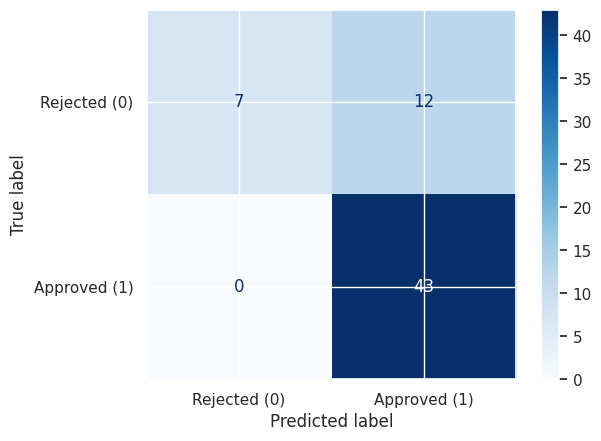

In [ ]:
#confusion matrix
y_pred = model.predict(X_val)

cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected (0)", "Approved (1)"]
).plot(cmap="Blues")

plt.show()

In [ ]:
import pandas as pd

# Generate predictions for the validation set
y_pred = model.predict(X_val)

# Combine the features, actual labels, and predictions
results = X_val.copy()
results["Actual_Status"] = y_val
results["Predicted_Status"] = y_pred

# Actual rejected applications incorrectly predicted as approved
missed_rejections = results[
    (results["Actual_Status"] == 0) &
    (results["Predicted_Status"] == 1)
]

print("Number of rejected applications misclassified:",
      len(missed_rejections))

print(missed_rejections)

Number of rejected applications misclassified: 12
     Dependents  ApplicantIncome  CoapplicantIncome  LoanAmount  \
340        1.00             2647             1587.0       173.0   
77         0.50             1000             3022.0       110.0   
546        0.25             3358                0.0        80.0   
53         0.75             4616                0.0       134.0   
181        0.25             1916             5063.0        67.0   
573        0.75             6125             1625.0       187.0   
216        0.25              150             1800.0       135.0   
314        0.25             2473             1843.0       159.0   
152        0.25             9166                0.0       244.0   
417        0.75             1600            20000.0       239.0   
513        0.25             2130             6666.0        70.0   
31         0.25             3167                0.0        74.0   

     Loan_Amount_Term  Credit_History  Gender_Female  Gender_Male  Married_No 

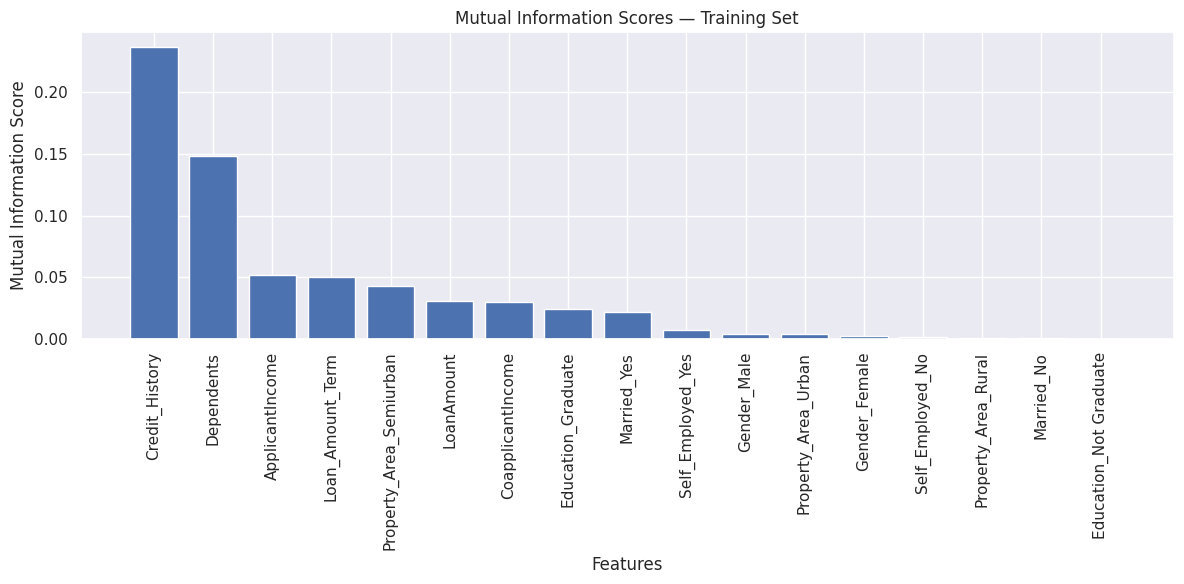

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

# Use training data only
X = X_train
y = y_train

feature_names = X.columns

# Identify categorical / binary encoded columns.
# Adjust this list to match your actual column names.
discrete_cols = [
    col for col in X.columns
    if col.startswith((
        "Gender_", "Married_", "Education_",
        "Self_Employed_", "Property_Area_"
    ))
    or col in ["Credit_History", "Dependents"]
]

discrete_mask = X.columns.isin(discrete_cols)

# Calculate MI scores
scores = mutual_info_classif(
    X, y,
    discrete_features=discrete_mask,
    random_state=42
)

# Sort scores from highest to lowest
indices = np.argsort(scores)[::-1]
sorted_scores = scores[indices]
sorted_feature_names = feature_names[indices]

# Plot
plt.figure(figsize=(12, 6))
plt.bar(range(len(sorted_scores)), sorted_scores)
plt.xticks(
    range(len(sorted_scores)),
    sorted_feature_names,
    rotation=90
)
plt.title("Mutual Information Scores — Training Set")
plt.xlabel("Features")
plt.ylabel("Mutual Information Score")
plt.tight_layout()
plt.show()